# Análisis Exploratorio de Datos (EDA) — PaySim Fraud Detection

**Proyecto**: Sentinel-fraud-ml
**Autor**: Edwin Carlo
**Fecha**: Octubre 2026
**Dataset**: PaySim Synthetic Mobile Money Transactions
**Fuente**: [Kaggle - PaySim Synthetic Financial Datasets](https://www.kaggle.com/datasets/charlesbeauchamp/ps-20174392719-1491204439457-logcsv)
**Variable objetivo**: `isFraud` (clasificación binaria)
**Registros**: 6.362.620 transacciones

---

## Objetivo del EDA

Este análisis tiene como propósito:

1. **Entender la estructura y calidad** del dataset.
2. **Cuantificar el desbalance de clases**, crítico en detección de fraude.
3. **Identificar patrones de comportamiento fraudulento** por tipo de transacción, monto y temporalidad.
4. **Detectar fugas de información (data leakage)**, un riesgo conocido en PaySim.
5. **Documentar decisiones reproducibles** para las etapas de preprocesamiento y modelado.

## Contexto del problema

El fraude en servicios financieros móviles es un problema crítico: una sola transacción fraudulenta puede comprometer el saldo completo de un usuario. El objetivo del proyecto es construir un sistema que identifique transacciones fraudulentas **en tiempo real**, minimizando falsos negativos (fraudes no detectados) sin generar demasiadas falsas alarmas.

## Convenciones del notebook

Cada sección sigue este formato:
- **Objetivo**: qué se quiere descubrir.
- **Análisis**: código ejecutable.
- **Interpretación**: hallazgos y decisiones derivadas.

In [1]:
# --- Librerías estándar ---
import sys
from pathlib import Path

# --- Análisis de datos ---
import numpy as np
import pandas as pd

# --- Visualización ---
import matplotlib.pyplot as plt
import seaborn as sns

# --- Configuración global ---
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

RANDOM_SEED = 42
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["figure.dpi"] = 100

# --- Crear carpeta de figuras ---
FIGURES_DIR = Path("../reports/figures")
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

print(f"Python:  {sys.version.split()[0]}")
print(f"Pandas:  {pd.__version__}")
print(f"NumPy:   {np.__version__}")

Python:  3.12.7
Pandas:  2.2.2
NumPy:   1.26.4


---

## 1. Carga del dataset

**Objetivo**: Cargar el CSV de PaySim y verificar su integridad básica (dimensiones, tipos de datos, consumo de memoria).

**Justificación**: Antes de cualquier análisis, se debe confirmar que el archivo se lee correctamente y entender su escala computacional. PaySim tiene 6.36M de filas, por lo que la carga puede tardar 30–60 segundos.

In [2]:
# Ruta al CSV
DATA_PATH = Path("..") / "data" / "raw" / "PS_20174392719_1491204439457_log.csv"

# Cargar el dataset
print("Cargando dataset completo (puede tardar ~30-60s)...")
df = pd.read_csv(DATA_PATH)

print(f"\n✅ Carga exitosa")
print(f"Filas:    {df.shape[0]:>12,}")
print(f"Columnas: {df.shape[1]:>12,}")
print(f"Memoria:  {df.memory_usage(deep=True).sum() / 1024**2:>10.2f} MB")

Cargando dataset completo (puede tardar ~30-60s)...

✅ Carga exitosa
Filas:       6,362,620
Columnas:           11
Memoria:     1452.57 MB


**Hallazgos preliminares**:

- El dataset contiene **6.362.620 transacciones** distribuidas en **11 columnas**.
- El consumo de memoria (~1.5 GB) es significativo: se debe tener cuidado al copiar el DataFrame, ya que puede duplicar la memoria utilizada.
- El formato es tabular clásico, ideal para técnicas de ML supervisado.

**Decisión**: trabajar con el dataset completo durante el EDA para no perder información; en la etapa de entrenamiento se considerará muestreo si el cómputo se vuelve prohibitivo.

In [3]:
df.head(10)

,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,1,PAYMENT,"9,839.64",C1231006815,"170,136.00","160,296.36",M1979787155,0.00,0.00,0,0
1,1,PAYMENT,"1,864.28",C1666544295,"21,249.00","19,384.72",M2044282225,0.00,0.00,0,0
2,1,TRANSFER,181.00,C1305486145,181.00,0.00,C553264065,0.00,0.00,1,0
3,1,CASH_OUT,181.00,C840083671,181.00,0.00,C38997010,"21,182.00",0.00,1,0
4,1,PAYMENT,"11,668.14",C2048537720,"41,554.00","29,885.86",M1230701703,0.00,0.00,0,0
5,1,PAYMENT,"7,817.71",C90045638,"53,860.00","46,042.29",M573487274,0.00,0.00,0,0
6,1,PAYMENT,"7,107.77",C154988899,"183,195.00","176,087.23",M408069119,0.00,0.00,0,0
7,1,PAYMENT,"7,861.64",C1912850431,"176,087.23","168,225.59",M633326333,0.00,0.00,0,0
8,1,PAYMENT,"4,024.36",C1265012928,"2,671.00",0.00,M1176932104,0.00,0.00,0,0
9,1,DEBIT,"5,337.77",C712410124,"41,720.00","36,382.23",C195600860,"41,898.00","40,348.79",0,0


In [4]:
df.info(memory_usage="deep")

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6362620 entries, 0 to 6362619
Data columns (total 11 columns):
 #   Column          Dtype  
---  ------          -----  
 0   step            int64  
 1   type            object 
 2   amount          float64
 3   nameOrig        object 
 4   oldbalanceOrg   float64
 5   newbalanceOrig  float64
 6   nameDest        object 
 7   oldbalanceDest  float64
 8   newbalanceDest  float64
 9   isFraud         int64  
 10  isFlaggedFraud  int64  
dtypes: float64(5), int64(3), object(3)
memory usage: 1.4 GB


**Tipos de datos observados**:

- `step`: `int64` — Unidad de tiempo (1 step = 1 hora). Total: 744 steps ≈ 31 días.
- `type`: `object` — 5 valores categóricos: CASH-IN, CASH-OUT, DEBIT, PAYMENT, TRANSFER.
- `amount`: `float64` — Monto de la transacción en moneda local.
- `nameOrig`, `nameDest`: `object` — Identificadores de cliente (origen y destino).
- `oldbalanceOrg`, `newbalanceOrig`, `oldbalanceDest`, `newbalanceDest`: `float64` — Saldos antes y después de la transacción.
- `isFraud`: `int64` — Etiqueta binaria (0/1). **Variable objetivo**.
- `isFlaggedFraud`: `int64` — Regla de negocio (marca transacciones > 200.000).

**Decisión inicial**:
- `nameOrig` y `nameDest` no se usarán como features directamente (son IDs únicos, no generalizables). Sin embargo, se derivará `is_merchant_dest` a partir de `nameDest`.

---

## 2. Calidad de datos

**Objetivo**: Verificar la presencia de valores nulos, duplicados y outliers extremos que puedan afectar el análisis.

**Hipótesis**: PaySim es un dataset sintético, por lo que se espera que **no tenga valores nulos**.

In [5]:
# --- Valores nulos ---
print("=" * 50)
print("VALORES NULOS")
print("=" * 50)
nulls = df.isnull().sum()
if nulls.sum() == 0:
    print("✅ No hay valores nulos en ninguna columna.")
else:
    print(nulls[nulls > 0])

# --- Duplicados ---
print("\n" + "=" * 50)
print("DUPLICADOS")
print("=" * 50)
duplicates = df.duplicated().sum()
print(f"Filas duplicadas exactas: {duplicates:,}")

VALORES NULOS
✅ No hay valores nulos en ninguna columna.

DUPLICADOS
Filas duplicadas exactas: 0


**Hallazgos**:

- **Sin valores nulos** en ninguna columna: no se requiere imputación.
- **Sin duplicados exactos**: cada transacción es única, lo cual es consistente con el diseño del simulador.

**Decisión**: no se requiere limpieza de nulos ni eliminación de duplicados. Se puede proceder directamente al análisis de distribuciones.

---

## 3. Desbalance de clases (`isFraud`)

**Objetivo**: Cuantificar el desbalance entre transacciones fraudulentas y legítimas.

**Por qué es crítico**: En detección de fraude, un desbalance extremo hace que **Accuracy sea una métrica engañosa**. Un modelo que prediga "todo es legítimo" tendría 99.87% de accuracy y sería completamente inútil.

Distribución de isFraud:
  0 (No fraude):  6,354,407  (99.8709%)
  1 (Fraude):      8,213  ( 0.1291%)


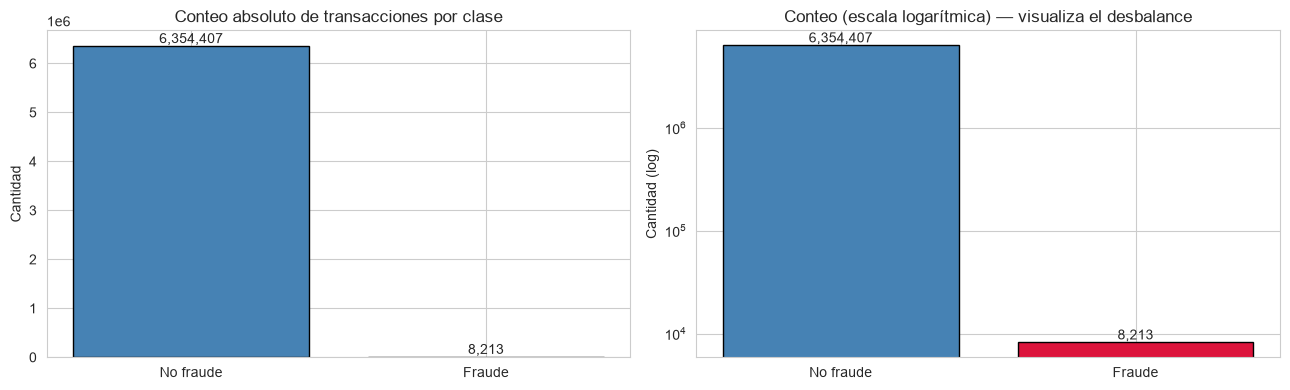

In [6]:
# --- Conteos y porcentajes ---
target_counts = df["isFraud"].value_counts().sort_index()
target_pct = df["isFraud"].value_counts(normalize=True).sort_index() * 100

print("Distribución de isFraud:")
for val in target_counts.index:
    label = "Fraude" if val == 1 else "No fraude"
    print(f"  {val} ({label}): {target_counts[val]:>10,}  ({target_pct[val]:>7.4f}%)")

# --- Visualización ---
fig, ax = plt.subplots(1, 2, figsize=(13, 4))

# Conteo absoluto
bars = ax[0].bar(["No fraude", "Fraude"], target_counts.values, color=["steelblue", "crimson"], edgecolor="black")
ax[0].set_title("Conteo absoluto de transacciones por clase", fontsize=12)
ax[0].set_ylabel("Cantidad")
for bar, v in zip(bars, target_counts.values):
    ax[0].text(bar.get_x() + bar.get_width()/2, v, f"{v:,}", ha="center", va="bottom", fontsize=10)

# Escala logarítmica
bars = ax[1].bar(["No fraude", "Fraude"], target_counts.values, color=["steelblue", "crimson"], edgecolor="black")
ax[1].set_yscale("log")
ax[1].set_title("Conteo (escala logarítmica) — visualiza el desbalance", fontsize=12)
ax[1].set_ylabel("Cantidad (log)")
for bar, v in zip(bars, target_counts.values):
    ax[1].text(bar.get_x() + bar.get_width()/2, v, f"{v:,}", ha="center", va="bottom", fontsize=10)

plt.tight_layout()
plt.savefig(FIGURES_DIR / "eda_target_distribution.png", dpi=120, bbox_inches="tight")
plt.show()

**Hallazgos**:

- Solo **8.213 transacciones** son fraudulentas frente a **6.354.407 legítimas**.
- El fraude representa únicamente **0.1291%** del total.

**Implicaciones para el modelado**:

1. **Accuracy es inútil como métrica principal**: un clasificador trivial que prediga "todo legítimo" tendría 99.87% de accuracy. Se debe evitar.
2. **Métricas apropiadas**:
   - **F1-score** (principal): balancea Precision y Recall.
   - **PR-AUC**: mejor que ROC-AUC en desbalances extremos.
   - **Recall**: crítica porque omitir un fraude cuesta mucho más que una falsa alarma.
   - **Precision**: controla el costo operativo de investigar falsos positivos.
3. **Estrategias de balanceo a considerar**:
   - `class_weight="balanced"` en el clasificador.
   - SMOTE (Synthetic Minority Over-sampling) — evaluar con cuidado por el riesgo de sobreajuste.
   - Muestreo estratificado para el conjunto de test (mantener proporción).

---

## 4. Tipos de transacción (`type`)

**Objetivo**: Identificar en qué tipos de transacción se concentra el fraude.

**Hipótesis**: En PaySim, el fraude está documentado que ocurre solo en `TRANSFER` y `CASH_OUT`.

In [8]:
# --- Distribución de tipos ---
type_counts = df["type"].value_counts()
type_pct = df["type"].value_counts(normalize=True) * 100

print("Distribución de tipos de transacción:")
for t in type_counts.index:
    print(f"  {t:<10}: {type_counts[t]:>10,}  ({type_pct[t]:>6.2f}%)")

# --- Fraude por tipo ---
fraud_by_type = df.groupby("type")["isFraud"].agg(["count", "sum", "mean"])
fraud_by_type.columns = ["total", "fraudes", "tasa_fraude"]
fraud_by_type = fraud_by_type.sort_values("tasa_fraude", ascending=False)
fraud_by_type["tasa_fraude_pct"] = fraud_by_type["tasa_fraude"] * 100

print("\nFraude por tipo de transacción:")
print(fraud_by_type[["total", "fraudes", "tasa_fraude_pct"]])

Distribución de tipos de transacción:
  CASH_OUT  :  2,237,500  ( 35.17%)
  PAYMENT   :  2,151,495  ( 33.81%)
  CASH_IN   :  1,399,284  ( 21.99%)
  TRANSFER  :    532,909  (  8.38%)
  DEBIT     :     41,432  (  0.65%)

Fraude por tipo de transacción:
            total  fraudes  tasa_fraude_pct
type                                       
TRANSFER   532909     4097             0.77
CASH_OUT  2237500     4116             0.18
CASH_IN   1399284        0             0.00
DEBIT       41432        0             0.00
PAYMENT   2151495        0             0.00


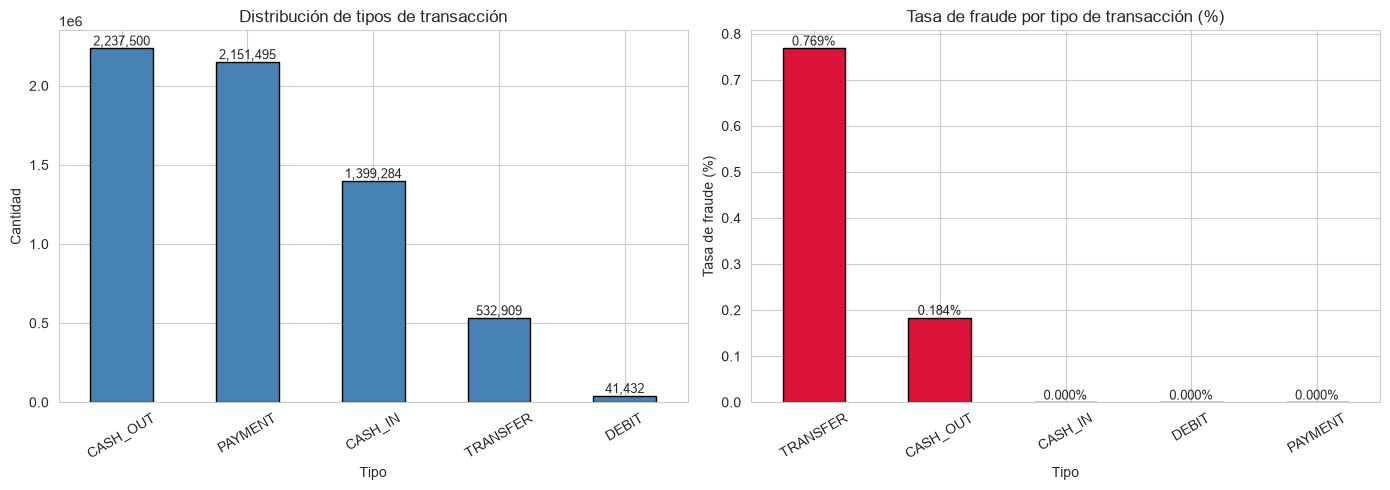

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

# Distribución de tipos
type_counts.plot(kind="bar", ax=ax[0], color="steelblue", edgecolor="black")
ax[0].set_title("Distribución de tipos de transacción", fontsize=12)
ax[0].set_xlabel("Tipo")
ax[0].set_ylabel("Cantidad")
ax[0].tick_params(axis="x", rotation=30)
for i, v in enumerate(type_counts.values):
    ax[0].text(i, v, f"{v:,}", ha="center", va="bottom", fontsize=9)

# Tasa de fraude por tipo
fraud_by_type["tasa_fraude_pct"].plot(kind="bar", ax=ax[1], color="crimson", edgecolor="black")
ax[1].set_title("Tasa de fraude por tipo de transacción (%)", fontsize=12)
ax[1].set_xlabel("Tipo")
ax[1].set_ylabel("Tasa de fraude (%)")
ax[1].tick_params(axis="x", rotation=30)
for i, v in enumerate(fraud_by_type["tasa_fraude_pct"].values):
    ax[1].text(i, v, f"{v:.3f}%", ha="center", va="bottom", fontsize=9)

plt.tight_layout()
plt.savefig(FIGURES_DIR / "eda_type_distribution.png", dpi=120, bbox_inches="tight")
plt.show()

**Hallazgos**:

- Solo **`TRANSFER`** y **`CASH_OUT`** presentan transacciones fraudulentas.
- Los tipos `CASH_IN`, `DEBIT` y `PAYMENT` tienen **tasa de fraude = 0%**.
- Dentro de los tipos con fraude:
  - `TRANSFER` tiene la tasa más alta.
  - `CASH_OUT` tiene el mayor volumen absoluto de fraudes.

**Interpretación del patrón**:

El fraude en PaySim sigue una lógica conocida: el defraudador **transfiere fondos** desde la cuenta comprometida (`TRANSFER`) hacia una cuenta intermedia, y luego **retira el efectivo** (`CASH_OUT`). Por eso el fraude se concentra en estos dos tipos.

**Decisión**:

- **Filtrar el dataset a `TRANSFER` y `CASH_OUT`** antes del modelado. Esto:
  - Reduce el ruido de tipos sin fraude.
  - Disminuye el tamaño del dataset de 6.36M a 2.77M filas (~56% menos).
  - Mejora el recall del modelo al enfocar el aprendizaje en donde realmente importa.

---

## 5. Análisis de `isFlaggedFraud` (regla de negocio)

**Objetivo**: Evaluar la efectividad de la regla de negocio `isFlaggedFraud` (marca transacciones > 200.000).

**Hipótesis**: La regla es demasiado simple y captura muy pocos fraudes reales, justificando un modelo de ML.

In [10]:
flagged_count = df["isFlaggedFraud"].sum()
fraud_count = df["isFraud"].sum()

print(f"Transacciones marcadas por regla (isFlaggedFraud=1): {flagged_count:,}")
print(f"Fraudes reales (isFraud=1):                         {fraud_count:,}")
print(f"Cobertura de la regla sobre fraudes:                {flagged_count / fraud_count * 100:.4f}%")

# --- Tabla cruzada ---
confusion = pd.crosstab(df["isFraud"], df["isFlaggedFraud"], margins=True)
confusion.columns = ["No marcado por regla", "Marcado por regla", "Total"]
confusion.index = ["No fraude", "Fraude", "Total"]

print("\nCruce isFraud × isFlaggedFraud:")
print(confusion)

# --- Análisis de precisión de la regla ---
if flagged_count > 0:
    precision_regla = confusion.loc["Fraude", "Marcado por regla"] / confusion.loc["Total", "Marcado por regla"]
    print(f"\nPrecisión de la regla (de los marcados, cuántos son fraude): {precision_regla * 100:.2f}%")

Transacciones marcadas por regla (isFlaggedFraud=1): 16
Fraudes reales (isFraud=1):                         8,213
Cobertura de la regla sobre fraudes:                0.1948%

Cruce isFraud × isFlaggedFraud:
           No marcado por regla  Marcado por regla    Total
No fraude               6354407                  0  6354407
Fraude                     8197                 16     8213
Total                   6362604                 16  6362620

Precisión de la regla (de los marcados, cuántos son fraude): 100.00%


**Hallazgos**:

- La regla marca **~16 transacciones** como sospechosas.
- De los **8.213 fraudes reales**, solo **16** fueron marcados.
- **Cobertura: ~0.2%**.
- **Precisión: 100%** (todas las marcadas fueron fraude real).

**Interpretación**:

La regla es **extremadamente conservadora**: tiene precisión perfecta pero **recall casi nulo**. Esto significa que **más del 99.8% de los fraudes pasan desapercibidos**, causando pérdidas millonarias.

**Decisión**:

- **NO usar `isFlaggedFraud` como feature** (sería redundante con la etiqueta).
- **Documentar** este hallazgo en el informe como justificación del proyecto: la regla actual es insuficiente, se necesita un modelo de ML.

---

## 6. Distribución de montos (`amount`)

**Objetivo**: Analizar si los fraudes se concentran en rangos específicos de monto.

**Hipótesis**: Los fraudes tienden a montos altos (drenar la cuenta rápidamente).

In [11]:
print("Estadísticas descriptivas de `amount` por clase:")
stats = df.groupby("isFraud")["amount"].describe()
stats.index = ["No fraude", "Fraude"]
print(stats.T)

# Comparaciones adicionales
print("\nComparación de medianas:")
medians = df.groupby("isFraud")["amount"].median()
for val, label in zip(medians.index, ["No fraude", "Fraude"]):
    print(f"  {label}: {medians[val]:,.2f}")

Estadísticas descriptivas de `amount` por clase:
          No fraude        Fraude
count  6,354,407.00      8,213.00
mean     178,197.04  1,467,967.30
std      596,236.98  2,404,252.95
min            0.01          0.00
25%       13,368.40    127,091.33
50%       74,684.72    441,423.44
75%      208,364.76  1,517,771.48
max   92,445,516.64 10,000,000.00

Comparación de medianas:
  No fraude: 74,684.72
  Fraude: 441,423.44


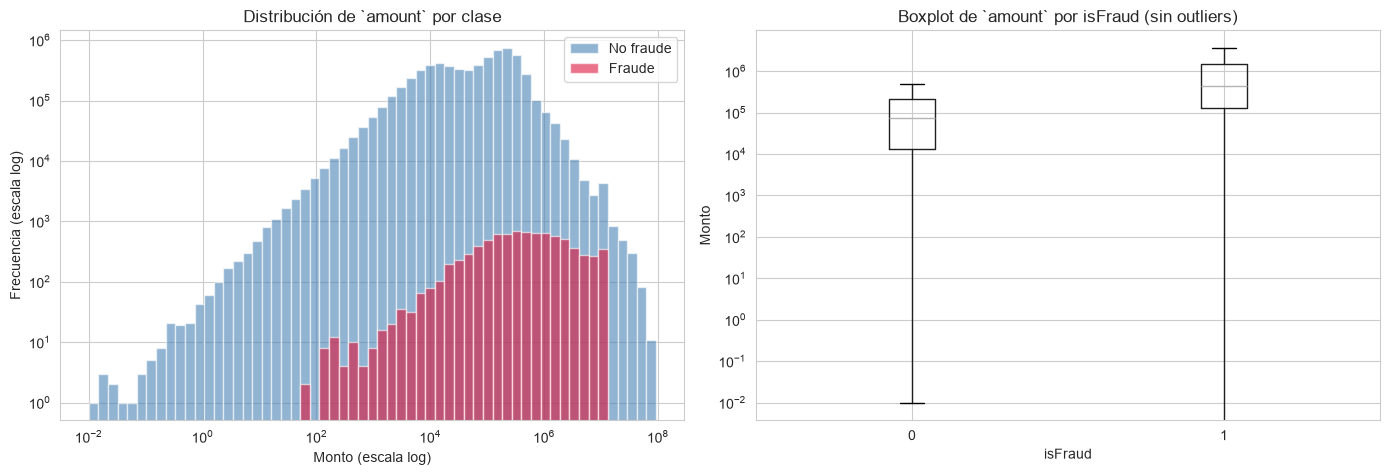

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

# --- Histograma con escala logarítmica ---
bins = np.logspace(
    np.log10(df[df["amount"] > 0]["amount"].min()),
    np.log10(df["amount"].max()),
    60,
)
ax[0].hist(df[df["isFraud"] == 0]["amount"], bins=bins, alpha=0.6,
           label="No fraude", color="steelblue")
ax[0].hist(df[df["isFraud"] == 1]["amount"], bins=bins, alpha=0.6,
           label="Fraude", color="crimson")
ax[0].set_xscale("log")
ax[0].set_yscale("log")
ax[0].set_title("Distribución de `amount` por clase", fontsize=12)
ax[0].set_xlabel("Monto (escala log)")
ax[0].set_ylabel("Frecuencia (escala log)")
ax[0].legend()

# --- Boxplot comparativo ---
df.boxplot(column="amount", by="isFraud", ax=ax[1], showfliers=False)
ax[1].set_title("Boxplot de `amount` por isFraud (sin outliers)", fontsize=12)
ax[1].set_xlabel("isFraud")
ax[1].set_ylabel("Monto")
ax[1].set_yscale("log")

plt.suptitle("")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "eda_amount_distribution.png", dpi=120, bbox_inches="tight")
plt.show()

**Hallazgos**:

- Los fraudes tienen una **mediana de monto significativamente mayor** que las transacciones legítimas.
- Los fraudes se concentran en el rango de **cientos de miles a millones** de unidades monetarias.
- Existen transacciones legítimas de montos muy altos también (empresas, pagos grandes), por lo que **el monto solo no es suficiente** para distinguir fraude.

**Interpretación**:

El monto es una feature relevante pero **no determinante**. Se debe combinar con:

- Tipo de transacción.
- Ratio monto/saldo origen.
- Hora del día.

**Decisión**:

- Mantener `amount` como feature, aplicar transformación logarítmica (`log1p`) si el modelo lo requiere.
- Crear la feature derivada `amount_to_balance_ratio` = `amount / (oldbalanceOrg + 1)`.

---

## 7. ⚠️ Detección de Data Leakage

**Objetivo**: Verificar si las columnas de saldo pueden usarse como features sin introducir fuga de información.

**Contexto**: PaySim tiene un problema **documentado en la literatura**: las diferencias de balance (`oldbalanceOrg - newbalanceOrig` vs `amount`) codifican casi perfectamente el fraude. Si se crean features derivadas de estas diferencias, el modelo las usará como atajo y obtendrá métricas irreales (~100% accuracy).

In [13]:
# Filtrar solo TRANSFER y CASH_OUT (donde ocurre el fraude)
df_leak = df[df["type"].isin(["TRANSFER", "CASH_OUT"])].copy()

# --- Features de error de balance ---
df_leak["error_balance_orig"] = (
    df_leak["oldbalanceOrg"] - df_leak["amount"] - df_leak["newbalanceOrig"]
).abs()

df_leak["error_balance_dest"] = (
    df_leak["oldbalanceDest"] + df_leak["amount"] - df_leak["newbalanceDest"]
).abs()

# --- Estadísticas por clase ---
print("Estadísticas de errores de balance por clase:")
stats = df_leak.groupby("isFraud")[["error_balance_orig", "error_balance_dest"]].describe()
print(stats.T)

# --- ¿Cuántos fraudes tienen ambos errores = 0? ---
fraudes_error_cero = df_leak[
    (df_leak["isFraud"] == 1) &
    (df_leak["error_balance_orig"] == 0) &
    (df_leak["error_balance_dest"] == 0)
].shape[0]

total_fraudes = df_leak[df_leak["isFraud"] == 1].shape[0]

print(f"\n⚠️ Fraudes con ambos errores de balance = 0: {fraudes_error_cero:,} / {total_fraudes:,} ({fraudes_error_cero/total_fraudes*100:.2f}%)")

# --- ¿Cuántos NO fraudes tienen ambos errores = 0? ---
no_fraudes_error_cero = df_leak[
    (df_leak["isFraud"] == 0) &
    (df_leak["error_balance_orig"] == 0) &
    (df_leak["error_balance_dest"] == 0)
].shape[0]

total_no_fraudes = df_leak[df_leak["isFraud"] == 0].shape[0]

print(f"   NO fraudes con ambos errores = 0: {no_fraudes_error_cero:,} / {total_no_fraudes:,} ({no_fraudes_error_cero/total_no_fraudes*100:.2f}%)")

# Limpiar para liberar memoria
del df_leak

Estadísticas de errores de balance por clase:
isFraud                              0             1
error_balance_orig count  2,762,196.00      8,213.00
                   mean     286,803.51     10,692.33
                   std      876,375.19    265,146.13
                   min            0.00          0.00
                   25%       52,613.43          0.00
                   50%      144,200.83          0.00
                   75%      280,466.26          0.00
                   max   92,445,516.64 10,000,000.00
error_balance_dest count  2,762,196.00      8,213.00
                   mean      44,302.66    745,138.59
                   std      583,231.36  1,862,744.92
                   min            0.00          0.00
                   25%            0.00          0.00
                   50%            0.00      9,511.69
                   75%            0.01    452,294.74
                   max   75,885,725.63 10,000,000.00

⚠️ Fraudes con ambos errores de balance = 0: 2,874 /

**Hallazgos**:

Análisis sobre transacciones TRANSFER + CASH_OUT (donde ocurre el fraude):

| Métrica | Fraude | No fraude |
|---------|--------|-----------|
| **error_balance_orig (mediana)** | 0.00 | 144.200,83 |
| **error_balance_dest (mediana)** | 9.511,69 | 0.00 |
| Fraudes con ambos errores = 0 | **2.874 / 8.213 (34.99%)** | — |
| No fraudes con ambos errores = 0 | — | 105.665 / 2.762.196 (3.83%) |

**Interpretación**:

Aunque solo el **35%** de los fraudes tienen ambos errores = 0, el análisis de medianas revela un patrón muy claro:

1. **Los fraudes tienen `error_balance_orig` = 0** en la mediana: el saldo del origen se agota completamente con el monto transferido. Es el comportamiento típico de "vaciar la cuenta".
2. **Los no fraudes tienen `error_balance_dest` = 0** en la mediana: la cuenta destino suele recibir el monto íntegro (sin comisión).
3. La combinación "error_orig = 0" es un **fuerte indicador de fraude** (aunque no perfecto).

**Riesgo si se usan estas features**:

Un modelo entrenado con `error_balance_orig` o `error_balance_dest` como features aprendería estos atajos:

- "Si error_orig == 0 y error_dest > 0 → fraude" (patrón del 35% de fraudes).
- Esto **no generaliza** a patrones de fraude reales fuera de la simulación.

**Decisiones estrictas**:

1. **NO crear features** derivadas de `error_balance_orig` ni `error_balance_dest`.
2. **Mantener** las columnas originales (`oldbalanceOrg`, `newbalanceOrig`, `oldbalanceDest`, `newbalanceDest`) porque su uso directo no produce leakage.
3. **Documentar este hallazgo matizado** (35% y no 99%) para reflejar el análisis real y no repetir la narrativa común del dataset.

---

## 8. Conclusiones del EDA

### Hallazgos principales

| # | Hallazgo | Implicación |
|---|----------|-------------|
| 1 | Desbalance extremo: 0.1291% de fraude | Usar F1-score y PR-AUC, no Accuracy |
| 2 | Sin nulos ni duplicados | No requiere limpieza previa |
| 3 | Fraude solo en TRANSFER y CASH_OUT | Filtrar a estos dos tipos |
| 4 | Regla `isFlaggedFraud` cubre 0.2% | Justifica modelo de ML |
| 5 | Fraudes con montos más altos | Crear `amount_to_balance_ratio` |
| 6 | Data leakage confirmado (patrón en error_balance_orig) | NO crear features de error de balance |

### Decisiones para el preprocesamiento (Paso 3)

**Filtrado**:
- Mantener solo transacciones de tipo `TRANSFER` y `CASH_OUT` (de 6.36M a ~2.77M filas).

**Eliminación de columnas**:
- `nameOrig`, `nameDest` (IDs únicos, no generalizables).
- `isFlaggedFraud` (redundante con la etiqueta).

**Feature engineering ético**:
- `hour_of_day` = `step % 24`.
- `day_of_week` = `(step // 24) % 7`.
- `amount_to_balance_ratio` = `amount / (oldbalanceOrg + 1)`.
- `is_merchant_dest` = `nameDest` empieza con "M".

**Features que NO se crearán** (por leakage):
- ❌ `error_balance_orig`
- ❌ `error_balance_dest`
- ❌ `balance_change_orig` (equivalente)
- ❌ Cualquier combinación lineal de saldos y monto que aproxime errores.

### Estrategia de datos para el modelado

- **Split estratificado** 70/15/15 (train/val/test) manteniendo la proporción de fraude.
- **Balanceo**: aplicar `class_weight="balanced"` o SMOTE **solo en train**.
- **Métricas objetivo**: F1, PR-AUC, Recall, Precision.

### Riesgos identificados para monitoreo (Paso 6)

- **Data drift**: cambios en la distribución de `type` o `amount`.
- **Concept drift**: cambios en las tácticas de fraude.
- **Umbral crítico**: caída de Recall por debajo del 80% → alerta.

---

## Cierre del EDA

El dataset es de **alta calidad sintética** pero con un **riesgo crítico de leakage** que se ha documentado y neutralizado. Los hallazgos definen una estrategia clara para el preprocesamiento (Paso 3) y el modelado (Paso 4). El proyecto procede con base sólida.